![Original climate-globe illustration introducing Download, import, and audit a Pulse export; illustrative, not a data map](assets/atlas-splash.png)

# 31 · Download, import, and audit a Pulse export

**Guiding question:** Has a newer export added months, revised history, or changed its meaning?

**Data:** Real bundled Niño 3.4 CSV self-check by default; explicit optional learner-uploaded official monthly export  
**Time:** 20–35 minutes · **Prerequisites:** basic Python; run cells from top to bottom.  
**Author:** JupyterLite-C3S-Atlas contributors (AI assisted) · **Created/updated:** 2026-11-20  
**Inputs:** bundled reference files and/or seeded examples specified below. **Outputs:** tables, figures, and any explicitly named local exports; source data are not modified.  
**Runtime:** Python/Pyodide; NumPy, pandas, Matplotlib, Plotly; versions and tests are recorded in the validation report.  
**Change log:** initial educational chapter. **Contact:** [repository issues](https://github.com/jltobias/JupyterLite-C3S-Atlas/issues).

[Open in JupyterLite Lab](https://jltobias.github.io/JupyterLite-C3S-Atlas/lite/lab/index.html?path=31-pulse-download-roundtrip.ipynb) · [Official Atlas](https://atlas.climate.copernicus.eu/)


## Read the evidence

A live view is useful for exploration; a retained CSV is useful for reproduction.
        Open the official Niño 3.4 monthly view, select the CSV download control, and keep
        the whole file including its metadata header. In JupyterLite, create `uploads/`
        and upload the CSV as `pulse_export.csv`. Set `USE_UPLOADED_EXPORT = True`
        below only after checking the source. A missing or incompatible file stops with an
        explicit error; it is never silently relabelled as real data.

        **Browser download path:** the public CSV endpoint returned no cross-origin
        permission header when checked on 20 November 2026. Therefore this lesson uses
        normal browser download followed by Lab upload, rather than promising an automatic
        Pyodide fetch. Opening the CSV URL directly in a new tab is another download route.
        No proxy, token, or security-setting change is needed.

        The default example reads the bundled original export and audits it against itself:
        zero revisions are expected. After you explicitly select a new export, an outer date
        join distinguishes newly added months, removed months, and revisions to existing
        numbers. A changed value is not necessarily a data error: examine source processing,
        metadata, revisions, and rounding before interpreting the difference.

## Start the browser lab

Run this setup cell once. First load needs internet for the Python runtime and packages. The remaining lesson uses bundled data. If a 3D view is unavailable, use the 2D/table alternative. Download your edited notebook before clearing browser storage.

In [1]:
# Install only in the browser kernel; desktop dependencies come from requirements.txt.
import sys
if sys.platform == "emscripten":
    import piplite
    await piplite.install(["numpy", "pandas", "matplotlib", "plotly==6.5.0"])

import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from IPython.display import display
from atlas_helpers import (
    DATA, SYNTHETIC, COLORS, show, monthly_demo, anomalies, regular_grid,
    area_mean, coastlines, map_figure, globe_figure, warming_levels, load_monthly_csv,
)
print("Ready. Browser edits live in this browser; download work you want to keep.")


Ready. Browser edits live in this browser; download work you want to keep.


## Choose the source explicitly and retain the header

In [2]:
from app_helpers import pulse_link, complete_years, read_pulse_monthly_csv, compare_pulse_exports, apps_catalogue
from pulse_helpers import load_pulse, ANOM, REL
from IPython.display import Markdown
import hashlib
snapshot_path = DATA / "pulse/timeseries_era5_sst_monthly_nino34.csv"
snapshot_bytes = snapshot_path.read_bytes()
USE_UPLOADED_EXPORT = False  # Change only after downloading and uploading an official export.
chosen_path = Path("uploads/pulse_export.csv") if USE_UPLOADED_EXPORT else snapshot_path
raw = chosen_path.read_bytes()  # Missing uploaded files fail here, without fallback.
current, header = read_pulse_monthly_csv(raw)
baseline, baseline_header = read_pulse_monthly_csv(snapshot_bytes)
mode = "USER-UPLOADED EXPORT — review metadata" if USE_UPLOADED_EXPORT else "BUNDLED SNAPSHOT SELF-CHECK"
print(mode, "\nPath:", chosen_path, "\nSHA-256:", hashlib.sha256(raw).hexdigest())
print(header)
manifest = json.loads((DATA/"pulse/manifest.json").read_text(encoding="utf-8"))
source_url = next(r["url"] for r in manifest if r["file"].endswith(snapshot_path.name))
display(Markdown(f"[Open official monthly Niño 3.4]({pulse_link()}) · [Open the public source CSV]({source_url})"))

BUNDLED SNAPSHOT SELF-CHECK 
Path: C:\DATA\JupyterLite-C3S-Atlas\content\data\pulse\timeseries_era5_sst_monthly_nino34.csv 
SHA-256: e286b86e919c629faeea7b3dbdcf98a40ca0be6371dff517d73b0cab5bc7bafe
# Title: ERA5 monthly sea surface temperature, Nino 3.4 region
# Description: Sea surface temperature from ERA5, averaged over the region: monthly
#   means, from 1979-01-01 to 2026-10-01, with the climatology and anomalies relative to
#   1991-2020.
# Dataset:
#   ERA5, https://doi.org/10.24381/cds.f17050d7
# Region: Nino 3.4 region; ocean points only; 170W to 120W, 5S to 5N
# Averaging: area-weighted mean (cosine of latitude)
# Reference period: 1991-2020
# Units: degC
# Dates: first day of the month
# Columns:
#   date: first day of the month
#   sst: sea surface temperature (degC)
#   clim_1991_2020: climatology 1991-2020 (degC)
#   anom_1991_2020: anomaly relative to 1991-2020 (degC)
#   rnino_anom_1991_2020: relative Nino index, anomaly relative to 1991-2020 (degC)
# Notes:
#   Relativ

[Open official monthly Niño 3.4](https://pulse.climate.copernicus.eu/?variable=sst&region=nino-3-4&series=anomaly&map=anomaly&aggregation=monthly&date=2026-10-01) · [Open the public source CSV](https://sites.ecmwf.int/data/climatepulse/timeseries/csv/monthly/timeseries_era5_sst_monthly_nino34.csv)

## Distinguish additions from revisions

,Months
status,
unchanged,574
revised,0
new,0
removed,0


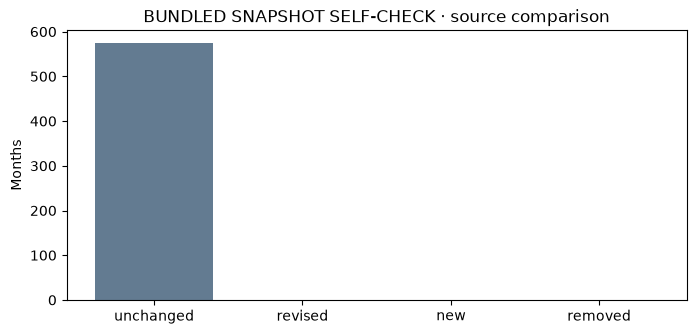

,date,sst_before,clim_1991_2020_before,anom_1991_2020_before,rnino_anom_1991_2020_before,sst_after,clim_1991_2020_after,anom_1991_2020_after,rnino_anom_1991_2020_after,_merge,status,anomaly_delta


In [3]:
audit = compare_pulse_exports(baseline, current)
counts = audit.status.value_counts().reindex(["unchanged","revised","new","removed"],fill_value=0)
display(counts.to_frame("Months"))
fig, ax = plt.subplots(figsize=(8,3.5))
ax.bar(counts.index,counts.values,color=["#637b91","#b95721","#087e8b","#80577f"])
ax.set(ylabel="Months",title=mode+" · source comparison"); plt.show()
display(audit[audit.status != "unchanged"].head(20))
if not USE_UPLOADED_EXPORT:
    assert counts["unchanged"] == len(baseline) and counts.drop("unchanged").sum() == 0

## Save a provenance sidecar without changing the source

In [4]:
from datetime import datetime, timezone
out = Path("exports"); out.mkdir(exist_ok=True)
evidence = {"mode":mode,"input_file":str(chosen_path),"sha256":hashlib.sha256(raw).hexdigest(),
    "audited_utc":datetime.now(timezone.utc).isoformat(),
    "official_source_url":source_url,"source_verified_by_learner":False,
    "retrieval_time_for_uploaded_file":"Record the actual download time; this audit time is not a retrieval time",
    "rows":len(current),"first_month":str(current.date.min().date()),"last_month":str(current.date.max().date()),
    "baseline":"1991–2020","units":"degC","licence":"CC-BY-4.0 per validated source header",
    "credit":"C3S / ECMWF / European Union; ERA5 teams",
    "transformation":"Parse original CSV; outer join by month; classify changes; raw bytes retained"}
(out/"pulse-import-audit.json").write_text(json.dumps(evidence,indent=2),encoding="utf-8")
print("Download exports/pulse-import-audit.json together with your original CSV and notebook.")

Download exports/pulse-import-audit.json together with your original CSV and notebook.


## Try it and explain

Download a fresh export, upload it, enable the explicit import switch, and rerun. Report its actual retrieval time and whether any common months changed. If none changed, say so.

**Interpretation check:** A new date is not a revision to an old date. The default self-check demonstrates the workflow but is not evidence that a live export was fetched.

## Transfer to the official tools

Use Pulse’s own export controls and retain the selected variable, region, aggregation, baseline, and app share URL. Check its credits before publishing a derived chart.

Record the selections, source version, units, periods, and uncertainty legend. These independent lessons do not duplicate every production workflow in the official tools.

## Sources and credit

- [C3S Atlas dataset and DOI](https://doi.org/10.24381/cds.h35hb680)
- [CSIC / Predictia Atlas user guide](https://confluence.ecmwf.int/spaces/CKB/pages/394237545/Copernicus+Interactive+Climate+Atlas+User+Guide)
- [Official C3S Atlas User Tools and contributors](https://ecmwf-projects.github.io/c3s-atlas/)
- [Official Climate Pulse](https://pulse.climate.copernicus.eu/)
- [Copernicus Data Stores Applications](https://apps.climate.copernicus.eu/)
- [Pulse source/data credits](https://pulse.climate.copernicus.eu/credits)
- [ERA5 monthly source](https://doi.org/10.24381/cds.f17050d7)

Original teaching text and code; original AI-generated splash illustration. Real reference files retain their source licences. Synthetic examples are not Copernicus measurements. See [credits](credits.md) and [data guide](data-guide.md).

**Continue:** [A field guide to the Copernicus apps](32-copernicus-apps-workshop.ipynb)